# 04 — Vented Box Design as a Constrained Optimisation

The goal is the **smallest vented box** that, driven at a fixed voltage $e_g$, reaches a target low-frequency extension $f_3$ without breaking the driver or vent limits.

The vent geometry has two independent quantities, the radius $a_v$ and the physical length $T$ (the area $S_v = \pi a_v^2$ is not a separate variable). Together with the volume they set the tuning:

$$f_b = \frac{c}{2\pi}\sqrt{\frac{S_v}{V\,L_{eff}}}, \qquad L_{eff} = T + \frac{8 a_v}{3\pi}$$

so $(V, a_v, T)$ and $(V, f_b, a_v)$ describe the same design. The second set is easier to work with:

$$\min_{V,\;f_b,\;a_v}\; V$$

subject to

| Constraint | Meaning |
|---|---|
| $f_3 \le f_{3,max}$ | low-frequency extension |
| $X_{peak}(f) \le X_{max}$ for every $f$ | cone excursion |
| $U_{v,peak}(f)\,/\,(\pi a_v^2) \le u_{max}$ for every $f$ | peak air speed in the vent |
| $a_v \ge a_{min}$ | smallest vent radius |
| $0 \le T(V, f_b, a_v) \le T_{max}$ | physical vent length |

The notebook follows these steps:

1. The response at the drive voltage
2. Eliminating the vent radius
3. Solving the reduced problem in $(V, f_b)$: no feasible design at 10 V
4. Adding a high-pass filter
5. The feasible region in $(V, f_b)$
6. A check of the design with the real `VentedBox`
7. How the minimum volume responds to each requirement and to the filter

In [99]:
import sys
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt

sys.path.append("..")

from src.components.driver import Driver
from src.components.filters import HighPassFilter
from src.components.radiation import MonopoleRadiation
from src.system import LoudspeakerSystem
from src.optimization import (
    Requirements,
    make_grid,
    vented_system,
    vent_length,
    performance,
    f3,
    shortest_vent_radius,
    evaluate,
    design_vented_box,
    max_spl_curve,
)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## Setup

- **Driver:** the same one used in notebooks 01 and 03.
- **Drive and target:** the terminal voltage $e_g$ (RMS) and the largest acceptable $f_3$. The constraints are evaluated on a log-spaced grid, so every octave has the same weight.
- **Limits:** peak vent air speed, minimum vent radius and maximum physical vent length.
- **Leakage:** $Q_L$ is fixed.

In [100]:
driver = Driver.from_thiele_small(
    Re=3.4,
    Le=1.43e-3,
    Fs=35.7,
    Qms=6.620,
    Qes=0.360,
    Vas=12.10e-3,
    Sd=124.7e-4,
    Xmax=6e-3,
    Pe=100,
)

band = (20, 200)   # Hz

req = Requirements(
    freqs=make_grid(*band, 200),
    voltage=12.0,
    max_f3=36.0,
    max_vent_speed=17.0,
    min_vent_radius=0.015,
    max_vent_length=0.40,
    Ql=7.0,
)

print(f"Drive:  {req.voltage:.2f} V RMS = {req.voltage**2 / driver.Re:.1f} W into Re (Pe = {driver.Pe:.0f} W)")
print(f"Xmax:   {1e3 * driver.Xmax:.1f} mm peak")

Drive:  12.00 V RMS = 42.4 W into Re (Pe = 100 W)
Xmax:   6.0 mm peak


# Step 1 — The response at the drive voltage

At fixed $V$ and $f_b$ the acoustic response does not depend on the vent radius. The box compliance is $C_{ab} = V/\rho c^2$, the vent mass is $M_{av} = 1/(\omega_b^2 C_{ab})$, and the losses $Q_L$, $Q_p$ are defined at $\omega_b$. The cone displacement $X_d(f)$, the vent volume velocity $U_v(f)$ and the pressure $p(f)$ are therefore functions of $(V, f_b)$ only.

Phasors are RMS while $X_{max}$ and the vent speed limit are peak values, so

$$X_{peak}(f) = \sqrt{2}\,|X_d(f)|, \qquad U_{v,peak}(f) = \sqrt{2}\,|U_v(f)|$$

**$f_3$.** The level is measured against the mass-controlled passband asymptote of a monopole radiating into half space:

$$L(f) = 20\log_{10}\frac{|p(f)|}{p_\infty(f)}, \qquad p_\infty = \frac{\rho_0\,Bl\,S_d\,e_g}{2\pi r\,M_{ms}\,|Z_e(f)|}$$

$|Z_e|$ includes $L_e$, so $L(f) \to 0$ dB at high frequency. $f_3$ is the lowest frequency above which $L(f) \ge -3$ dB, so the requirement $f_3 \le f_{3,max}$ is the per-frequency constraint

$$L(f) \ge -3\ \text{dB} \quad \text{for every } f \ge f_{3,max}$$

Both $e_g$ and $r$ cancel in $L(f)$: **the $f_3$ constraint does not depend on the drive voltage**. The voltage only scales the excursion and the vent flow.

Below, a box of 20 L tuned to 38 Hz with a 3 cm vent radius (the box from notebook 03) is driven at $e_g$.

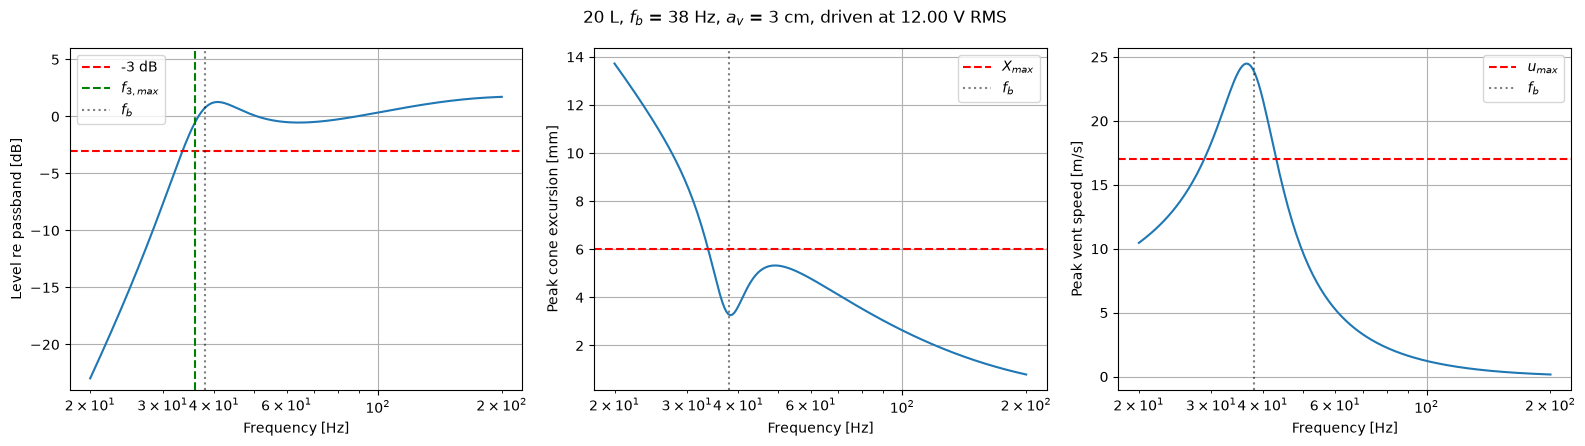

f3:                               33.5 Hz
Vent length for a 3 cm radius:  26.7 cm


In [101]:
volume, fb, radius = 20e-3, 38.0, 0.03   # m^3, Hz, m

perf = performance(vented_system(driver, volume, fb, Ql=req.Ql), req)
vent_speed = perf.vent_flow / (np.pi * radius**2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].semilogx(req.freqs, perf.level)
axes[0].axhline(-3, color="r", linestyle="--", label="-3 dB")
axes[0].axvline(req.max_f3, color="g", linestyle="--", label="$f_{3,max}$")
axes[0].set_ylabel("Level re passband [dB]")
axes[0].set_ylim(-24, 6)

axes[1].semilogx(req.freqs, 1e3 * perf.excursion)
axes[1].axhline(1e3 * driver.Xmax, color="r", linestyle="--", label="$X_{max}$")
axes[1].set_ylabel("Peak cone excursion [mm]")

axes[2].semilogx(req.freqs, vent_speed)
axes[2].axhline(req.max_vent_speed, color="r", linestyle="--", label="$u_{max}$")
axes[2].set_ylabel("Peak vent speed [m/s]")

for ax in axes:
    ax.axvline(fb, color="k", linestyle=":", alpha=0.5, label="$f_b$")
    ax.set_xlabel("Frequency [Hz]")
    ax.legend()

fig.suptitle(f"{1e3 * volume:.0f} L, $f_b$ = {fb:.0f} Hz, $a_v$ = {1e2 * radius:.0f} cm, driven at {req.voltage:.2f} V RMS")
fig.tight_layout()
plt.show()

print(f"f3:                               {f3(req.freqs, perf.level):.1f} Hz")
print(f"Vent length for a {1e2 * radius:.0f} cm radius:  {1e2 * vent_length(volume, fb, radius):.1f} cm")

# Step 2 — Eliminating the vent radius

The vent radius enters only through the vent speed $U_{v,peak}/(\pi a_v^2)$, which falls as the radius grows, and through the length that tunes the box to $f_b$:

$$T(a_v) = \frac{c^2\,\pi a_v^2}{\omega_b^2\,V} - \frac{8 a_v}{3\pi}$$

$T$ is a parabola in $a_v$ with roots at $0$ and $a_0 = \dfrac{8\,\omega_b^2 V}{3\pi^2 c^2}$, and it increases for every $a_v \ge a_0$. Every radius constraint is a lower bound except $T \le T_{max}$:

$$a_v \ge a_{min}, \qquad a_v \ge \sqrt{\frac{\max_f U_{v,peak}(f)}{\pi\,u_{max}}}, \qquad a_v \ge a_0 \;\;(T \ge 0)$$

The best choice at each $(V, f_b)$ is therefore the smallest radius that meets all of them, which is also the shortest vent:

$$a_v^* = \max\left(a_{min},\ \sqrt{\frac{\max_f U_{v,peak}}{\pi\,u_{max}}},\ a_0\right)$$

and $(V, f_b)$ is feasible for the vent if and only if $T(a_v^*) \le T_{max}$.

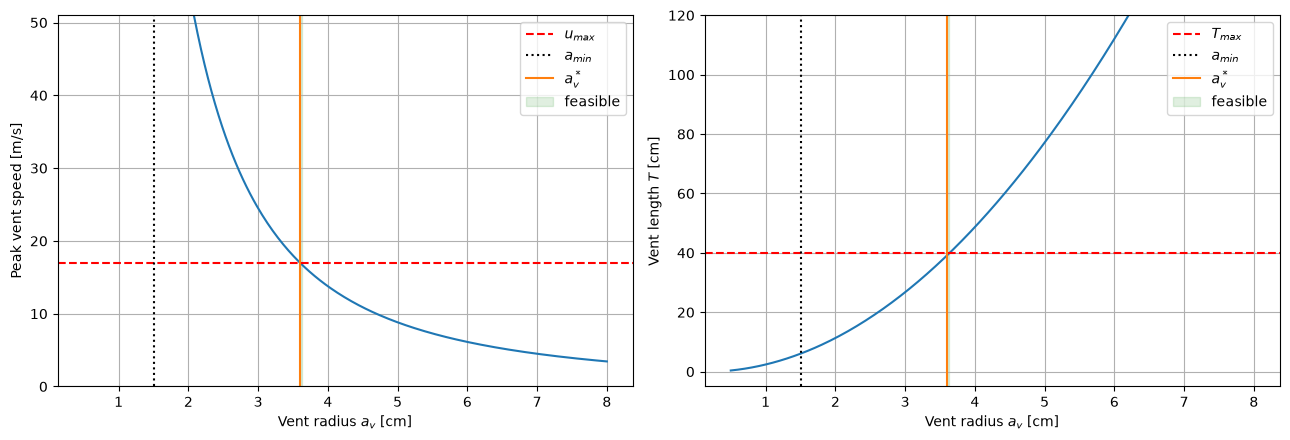

a_v* = 3.60 cm, T(a_v*) = 39.1 cm


In [102]:
radii = np.linspace(0.005, 0.08, 300)
speed = perf.vent_flow.max() / (np.pi * radii**2)
length = vent_length(volume, fb, radii)
best_radius = shortest_vent_radius(volume, fb, perf.vent_flow.max(), req)

ok = (
    (speed <= req.max_vent_speed)
    & (radii >= req.min_vent_radius)
    & (length >= 0)
    & (length <= req.max_vent_length)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(1e2 * radii, speed)
axes[0].axhline(req.max_vent_speed, color="r", linestyle="--", label="$u_{max}$")
axes[0].set_ylabel("Peak vent speed [m/s]")
axes[0].set_ylim(0, 3 * req.max_vent_speed)

axes[1].plot(1e2 * radii, 1e2 * length)
axes[1].axhline(1e2 * req.max_vent_length, color="r", linestyle="--", label="$T_{max}$")
axes[1].set_ylabel("Vent length $T$ [cm]")
axes[1].set_ylim(-5, 300 * req.max_vent_length)

for ax in axes:
    ax.axvline(1e2 * req.min_vent_radius, color="k", linestyle=":", label="$a_{min}$")
    ax.axvline(1e2 * best_radius, color="tab:orange", label="$a_v^*$")
    ax.fill_between(1e2 * radii, 0, 1, where=ok, transform=ax.get_xaxis_transform(), color="g", alpha=0.12, label="feasible")
    ax.set_xlabel("Vent radius $a_v$ [cm]")
    ax.legend()

fig.tight_layout()
plt.show()

print(f"a_v* = {1e2 * best_radius:.2f} cm, T(a_v*) = {1e2 * vent_length(volume, fb, best_radius):.1f} cm")

# Step 3 — Solving the reduced problem

With $a_v = a_v^*(V, f_b)$, the vent speed, minimum radius and $T \ge 0$ constraints hold by construction and the problem has two variables:

$$\min_{V,\;f_b}\; V \quad \text{subject to} \quad
\begin{cases}
1 - X_{peak}(f)/X_{max} \ge 0 & \text{for every } f \\
L(f)/3 + 1 \ge 0 & \text{for every } f \ge f_{3,max} \\
1 - T(V, f_b, a_v^*)/T_{max} \ge 0
\end{cases}$$

Each constraint is written as a normalised margin that holds where it is $\ge 0$. A margin of zero means the constraint is active: it is what stops the volume from shrinking further.

`design_vented_box` solves this with SLSQP. The problem is not convex, so the solver starts from a grid of $(V, f_b)$ initial guesses and keeps the smallest feasible result.

Feasible design at 12 V RMS without a filter: False


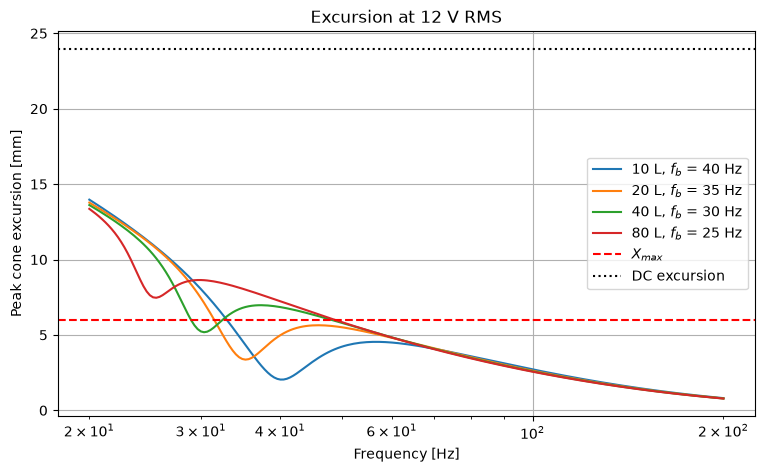

In [103]:
design = design_vented_box(driver, req)
print(f"Feasible design at {req.voltage:.0f} V RMS without a filter: {design is not None}")

dc_excursion = np.sqrt(2) * driver.Bl * req.voltage * driver.Cms / driver.Re

fig, ax = plt.subplots()
for volume_i, fb_i in [(10e-3, 40), (20e-3, 35), (40e-3, 30), (80e-3, 25)]:
    perf_i = performance(vented_system(driver, volume_i, fb_i, Ql=req.Ql), req)
    ax.semilogx(req.freqs, 1e3 * perf_i.excursion, label=f"{1e3 * volume_i:.0f} L, $f_b$ = {fb_i} Hz")
ax.axhline(1e3 * driver.Xmax, color="r", linestyle="--", label="$X_{max}$")
ax.axhline(1e3 * dc_excursion, color="k", linestyle=":", label="DC excursion")
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Peak cone excursion [mm]")
ax.set_title(f"Excursion at {req.voltage:.0f} V RMS")
ax.legend()
plt.show()

There is no feasible design at this drive level, and the plot shows why. Above $f_b$ the vent loads the cone and the excursion is small. Below $f_b$ the vent stops loading it, and towards DC the box applies no stiffness at all, so only the suspension resists:

$$X_{peak}(f \to 0) = \sqrt{2}\,\frac{Bl\,e_g\,C_{ms}}{R_e}$$

The excursion at the bottom of the band is therefore almost the same whatever $V$ and $f_b$ are. If it exceeds $X_{max}$ there, no box can fix it.

# Step 4 — Adding a high-pass filter

The standard fix is a subsonic high-pass filter ahead of the amplifier. It is modelled as an ideal line-level Butterworth filter $H(s)$ of order $n$ and corner $f_c$, which does not load the driver. The terminal voltage becomes

$$e(f) = e_g\,H(j2\pi f), \qquad |H(j2\pi f)| = \frac{1}{\sqrt{1 + (f_c/f)^{2n}}}$$

`HighPassFilter` is a component of `LoudspeakerSystem`, so the optimiser and the final check solve exactly the same system. The model is linear, so the filter scales every output by $H(f)$:

- **Excursion and vent flow** fall as $(f/f_c)^n$ below the corner, which removes the problem at the bottom of the band.
- **$f_3$** now belongs to the whole system. $L(f)$ is still measured against the *unfiltered* passband, so the filter's roll-off counts against the $f_3$ constraint.

A Butterworth filter is already $-3$ dB at its corner. With $f_c = f_{3,max}$ the box must therefore be close to flat at $f_{3,max}$, which costs volume. Step 7 explores lower corners.

High-pass:        order 4, corner 30.6 Hz
Volume:           15.00 L   (Vas = 12.1 L)
Tuning fb:        38.20 Hz
f3:               36.00 Hz   (maximum 36.0 Hz)
Vent radius:      3.15 cm
Vent length T:    40.0 cm

Smallest margin of each constraint:
  excursion    +0.0624
  f3           -0.0000  <- active
  vent_length  -0.0000  <- active


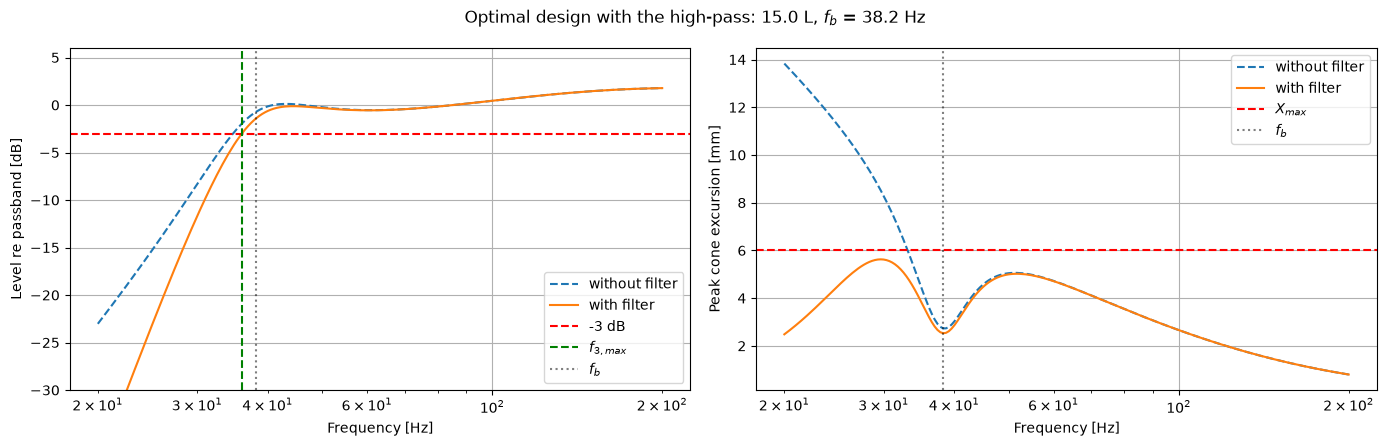

In [104]:
highpass = HighPassFilter(corner=req.max_f3*0.85, order=4)

design = design_vented_box(driver, req, highpass=highpass)
assert design is not None, "No feasible design for these requirements"

design_system = vented_system(driver, design.volume, design.fb, Ql=req.Ql, highpass=highpass)
design_perf = performance(design_system, req)

print(f"High-pass:        order {highpass.order}, corner {highpass.corner:.1f} Hz")
print(f"Volume:           {1e3 * design.volume:.2f} L   (Vas = {1e3 * driver.Vas():.1f} L)")
print(f"Tuning fb:        {design.fb:.2f} Hz")
print(f"f3:               {f3(req.freqs, design_perf.level):.2f} Hz   (maximum {req.max_f3:.1f} Hz)")
print(f"Vent radius:      {1e2 * design.vent_radius:.2f} cm")
print(f"Vent length T:    {1e2 * design.vent_length:.1f} cm")
print()
print("Smallest margin of each constraint:")
for name, margin in design.margins.items():
    flag = "  <- active" if margin.min() < 1e-3 else ""
    print(f"  {name:12s} {margin.min():+.4f}{flag}")

unfiltered = performance(vented_system(driver, design.volume, design.fb, Ql=req.Ql), req)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogx(req.freqs, unfiltered.level, "--", label="without filter")
axes[0].semilogx(req.freqs, design_perf.level, label="with filter")
axes[0].axhline(-3, color="r", linestyle="--", label="-3 dB")
axes[0].axvline(req.max_f3, color="g", linestyle="--", label="$f_{3,max}$")
axes[0].set_ylabel("Level re passband [dB]")
axes[0].set_ylim(-30, 6)

axes[1].semilogx(req.freqs, 1e3 * unfiltered.excursion, "--", label="without filter")
axes[1].semilogx(req.freqs, 1e3 * design_perf.excursion, label="with filter")
axes[1].axhline(1e3 * driver.Xmax, color="r", linestyle="--", label="$X_{max}$")
axes[1].set_ylabel("Peak cone excursion [mm]")

for ax in axes:
    ax.axvline(design.fb, color="k", linestyle=":", alpha=0.5, label="$f_b$")
    ax.set_xlabel("Frequency [Hz]")
    ax.legend()

fig.suptitle(f"Optimal design with the high-pass: {1e3 * design.volume:.1f} L, $f_b$ = {design.fb:.1f} Hz")
fig.tight_layout()
plt.show()

# Step 5 — The feasible region

With the vent radius eliminated, every point of the $(V, f_b)$ plane can be tested against all the constraints. Since the objective is the volume, the optimum is the leftmost point of the feasible region.

With the filter in place, the region is bounded by the $f_3$ constraint alone. The excursion constraint no longer appears in this plane, and the vent length only matters for small, low-tuned boxes in the bottom-left corner. The smallest volume is therefore the smallest box that can reach $f_{3,max}$ together with the filter, and the optimal $f_b$ is the tuning that achieves it.

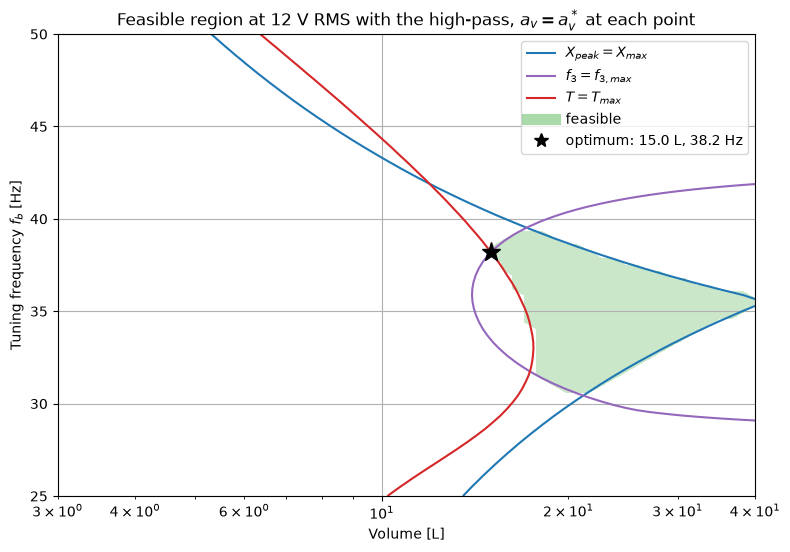

In [105]:
volumes = np.geomspace(3e-3, 40e-3, 60)
fbs = np.linspace(25, 50, 70)

names = list(design.margins)
margins = {name: np.zeros((len(volumes), len(fbs))) for name in names}

for i, volume_i in enumerate(volumes):
    for j, fb_j in enumerate(fbs):
        point = evaluate(driver, req, volume_i, fb_j, highpass=highpass)
        for name in names:
            margins[name][i, j] = point.margins[name].min()

feasible = np.all([m >= 0 for m in margins.values()], axis=0)
colors = {"excursion": "tab:blue", "f3": "tab:purple", "vent_length": "tab:red"}
labels = {"excursion": "$X_{peak} = X_{max}$", "f3": "$f_3 = f_{3,max}$", "vent_length": "$T = T_{max}$"}

fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(1e3 * volumes, fbs, feasible.T.astype(float), levels=[0.5, 1.5], colors=["tab:green"], alpha=0.25)
for name in names:
    ax.contour(1e3 * volumes, fbs, margins[name].T, levels=[0], colors=[colors[name]])
    ax.plot([], [], color=colors[name], label=labels[name])
ax.plot(1e3 * design.volume, design.fb, "k*", markersize=14)

ax.plot([], [], color="tab:green", alpha=0.4, linewidth=8, label="feasible")
ax.plot([], [], "k*", markersize=10, label=f"optimum: {1e3 * design.volume:.1f} L, {design.fb:.1f} Hz")

ax.set_xscale("log")
ax.set_xlabel("Volume [L]")
ax.set_ylabel("Tuning frequency $f_b$ [Hz]")
ax.set_title(f"Feasible region at {req.voltage:.0f} V RMS with the high-pass, $a_v = a_v^*$ at each point")
ax.legend()
plt.show()

# Step 6 — Check with the real `VentedBox`

The design is built as an actual `VentedBox` with the derived radius and length, which uses the real end correction rather than the shortcut inside the optimiser. The same `HighPassFilter` goes into the system. The constraints are recomputed on a much finer frequency grid. Peaks that fall between the optimiser's grid points can exceed a limit by a fraction of a percent; a denser grid in `req.freqs` reduces this.

The SPL plot shows the filtered response at the drive voltage next to the max-SPL curve, the loudest the box can play before the cone reaches $X_{max}$ or the terminals reach the thermal limit $\sqrt{P_e R_e}$. Both limits apply at the terminals, so the max-SPL curve is the same with or without the line-level filter. The filter only changes how much source voltage is needed to reach it.

fb from the box:       38.20 Hz
f3:                    36.00 Hz (maximum 36.0 Hz)
Peak cone excursion:   5.626 mm (Xmax 6.0 mm)
Peak vent air speed:   17.00 m/s (limit 17.0 m/s)
Vent radius:           3.15 cm (minimum 1.5 cm)
Vent length:           40.0 cm (maximum 40.0 cm)


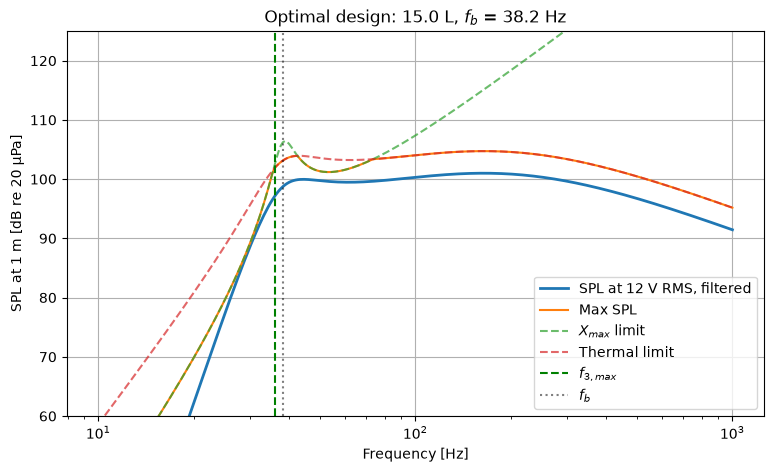

In [106]:
final_box = design.box(req)
final = LoudspeakerSystem(driver, final_box, radiation=MonopoleRadiation(), highpass=highpass)

check_req = replace(req, freqs=make_grid(*band, 400))
check = performance(final, check_req)
check_vent_speed = check.vent_flow / final_box.vent_area

print(f"fb from the box:       {final_box.vent_tuning_frequency():.2f} Hz")
print(f"f3:                    {f3(check_req.freqs, check.level):.2f} Hz (maximum {req.max_f3:.1f} Hz)")
print(f"Peak cone excursion:   {1e3 * check.excursion.max():.3f} mm (Xmax {1e3 * driver.Xmax:.1f} mm)")
print(f"Peak vent air speed:   {check_vent_speed.max():.2f} m/s (limit {req.max_vent_speed:.1f} m/s)")
print(f"Vent radius:           {1e2 * final_box.vent_radius:.2f} cm (minimum {1e2 * req.min_vent_radius:.1f} cm)")
print(f"Vent length:           {1e2 * final_box.vent_length:.1f} cm (maximum {1e2 * req.max_vent_length:.1f} cm)")

grid = make_grid(10, 1000, 300)
spl = final.solve(grid, voltage=req.voltage).spl
curve = max_spl_curve(final, grid)

plt.figure()
plt.semilogx(grid, spl, linewidth=2, label=f"SPL at {req.voltage:.0f} V RMS, filtered")
plt.semilogx(curve.frequency, curve.spl, label="Max SPL")
plt.semilogx(curve.frequency, curve.spl_excursion_limited, "--", alpha=0.7, label="$X_{max}$ limit")
plt.semilogx(curve.frequency, curve.spl_voltage_limited, "--", alpha=0.7, label="Thermal limit")
plt.axvline(req.max_f3, color="g", linestyle="--", label="$f_{3,max}$")
plt.axvline(final_box.vent_tuning_frequency(), color="k", linestyle=":", alpha=0.5, label="$f_b$")
plt.ylim(60, 125)
plt.xlabel("Frequency [Hz]")
plt.ylabel("SPL at 1 m [dB re 20 µPa]")
plt.title(f"Optimal design: {1e3 * design.volume:.1f} L, $f_b$ = {design.fb:.1f} Hz")
plt.legend()
plt.show()

# Step 7 — Sensitivity to each requirement and to the filter

Each requirement is varied on its own, with the others at the values from the setup, for a 2nd and a 4th order filter. In the first three panels the corner sits at $f_{3,max}$. Gaps in a curve are values for which no feasible design exists.

- **Drive voltage:** the volume does not change, since $f_3$ is independent of $e_g$. The limit (about 16 V for the 2nd order, 15 V for the 4th) is now the excursion hump just above $f_b$. That is in the passband, where the filter barely attenuates. A 4th order filter passes more just above its corner than a 2nd order one, so it reaches the limit first.
- **Maximum $f_3$:** this is the requirement that sets the volume. Both orders give the same curve, because both are $-3$ dB at $f_{3,max}$ and the $f_3$ constraint is the one that binds.
- **Maximum vent length:** free while the shortest vent fits. Below about 25 cm, the vent length becomes the active constraint and the box must grow, since a larger $V$ needs a shorter vent for the same $f_b$.
- **High-pass corner:** a corner at $f_{3,max}$ is safe but expensive. Moving it down lets the box itself roll off earlier, and the volume drops to about 10.6 L (2nd order) or 9.5 L (4th order) at $0.7\,f_{3,max}$. Lower still, the filter stops controlling the excursion below $f_b$: the 4th order needs a larger box at $0.65\,f_{3,max}$, and below that no design exists for either order. The steeper 4th order filter protects better at a given corner, so it reaches a smaller box. Above $f_{3,max}$ the filter eats into the $f_3$ budget and the volume grows quickly, faster for the 4th order.

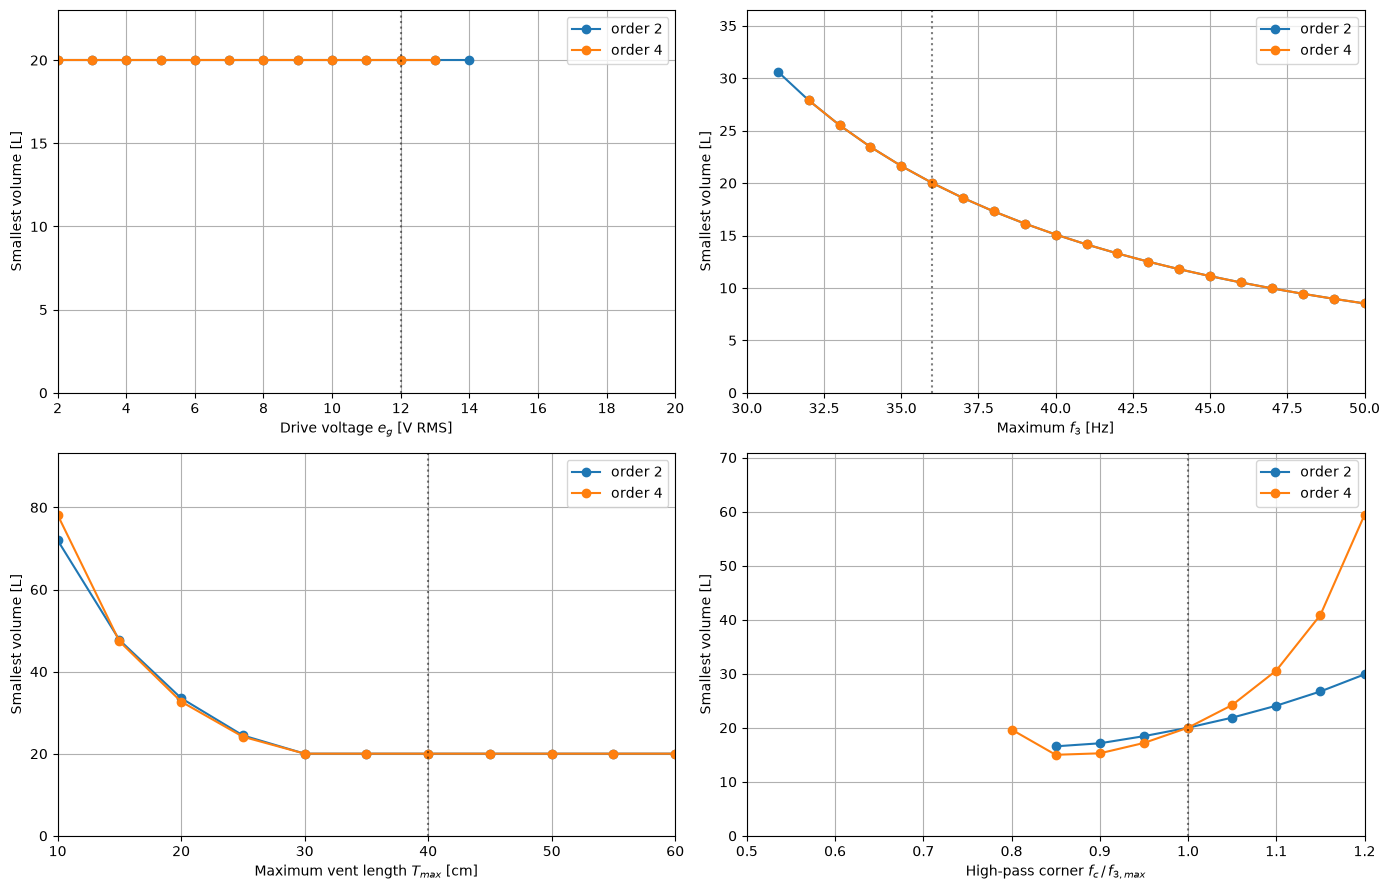

In [107]:
def smallest_volume(corner_ratio=1.0, order=2, **changes):
    """Smallest volume in L, with the high-pass corner placed at corner_ratio * max_f3."""
    sweep_req = replace(req, **changes)
    sweep_highpass = HighPassFilter(corner=corner_ratio * sweep_req.max_f3, order=order)
    result = design_vented_box(driver, sweep_req, highpass=sweep_highpass)
    return np.nan if result is None else 1e3 * result.volume


sweeps = [
    ("voltage", np.arange(2.0, 20.01, 1.0), 1.0, "Drive voltage $e_g$ [V RMS]"),
    ("max_f3", np.arange(30.0, 50.01, 1.0), 1.0, "Maximum $f_3$ [Hz]"),
    ("max_vent_length", np.arange(0.10, 0.61, 0.05), 1e2, "Maximum vent length $T_{max}$ [cm]"),
]
ratios = np.arange(0.5, 1.21, 0.05)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (name, values, scale, label) in zip(axes.flat, sweeps):
    for order in (2, 4):
        ax.plot(scale * values, [smallest_volume(order=order, **{name: value}) for value in values], "o-", label=f"order {order}")
    ax.axvline(scale * getattr(req, name), color="k", linestyle=":", alpha=0.5)
    ax.set_xlim(scale * values[0], scale * values[-1])
    ax.set_xlabel(label)

ax = axes.flat[3]
for order in (2, 4):
    ax.plot(ratios, [smallest_volume(corner_ratio=ratio, order=order) for ratio in ratios], "o-", label=f"order {order}")
ax.axvline(1.0, color="k", linestyle=":", alpha=0.5)
ax.set_xlim(ratios[0], ratios[-1])
ax.set_xlabel("High-pass corner $f_c\\,/\\,f_{3,max}$")

for ax in axes.flat:
    ax.set_ylabel("Smallest volume [L]")
    ax.set_ylim(0, 1.15 * ax.get_ylim()[1])
    ax.legend()

fig.tight_layout()
plt.show()